# MAGFiLO Panoptic Solar Filament Segmentation

**Author:** Robina Mirbahar  
**Dataset:** MAGFiLO 1.0 GONG H-alpha (2048x2048), 707 unique solar disks / 1,924 multi-annotator records  

This notebook verifies the modular three-stage pipeline implemented in `src/magfilo_panoptic/` and `train_magfilo_panoptic.py`:
1. **Stage P (Astrophysical Normalization):** 72-ray 50%-limb crossing + Kasa circle regression for `(cx, cy, R)`, 128-bin radial median Center-to-Limb Variation (CLV) flat-fielding, off-limb masking (`r > 0.995 R`), normalized-convolution chromospheric absorption contrast `(B_sigma48 - F) / B_sigma48`, and heliocentric cosine `mu`.
2. **Stage N (Topology-Aware Multi-Task Network):** 3-head (`fg`, `spine`, `sep`) `MagfiloPanopticUNet` with scSE attention, Pyramid Pooling bottleneck, stride-1 detail stem, boundary-upweighted `BCE + SoftDice`, and `0.25 * soft_clDice` (Shit et al., CVPR 2021).
3. **Stage H (Tree DP + Expected-PQ Calibration):** 7-superlevel laminar component tree on `P_eff = clip(0.75 P_fg + 0.25 P_spine - 0.35 P_sep, 0, 1)`, astrophysical sunspot rejection, 3-fold date-grouped LightGBM expected-PQ regressor `u_hat(c)`, bottom-up tree DP antichain optimization, and spine-tangent corridor bridging (`gap <= 14 px`).

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='.*IProgress not found.*')

import matplotlib.image as mpimg
import matplotlib.pyplot as plt

REPO_ROOT = Path('.').resolve()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import magfilo_panoptic as mp
print('Loaded magfilo_panoptic:', mp.__all__)

WEIGHTS_DIR = REPO_ROOT / 'weights'
with open(WEIGHTS_DIR / 'postproc_config.json', 'r', encoding='utf-8') as f:
    postproc_cfg = json.load(f)
print('Stored postproc_config.json:', json.dumps({
    k: postproc_cfg[k] for k in ('backbone', 'accelerator', 'infer_size', 'test_ensemble_folds', 'tau_optimal', 'tau_high_precision')
}, indent=2))
for p in sorted(WEIGHTS_DIR.iterdir()):
    print(f'  {p.name}: {p.stat().st_size / (1024 ** 2):.3f} MB')

Loaded magfilo_panoptic: ['IMG_SIZE', 'FEATURE_NAMES', 'encode_rle_counts', 'decode_rle_counts', 'rle_dict_from_counts', 'compute_exact_magfilo_metrics', 'estimate_solar_disk', 'preprocess_solar_disk', 'disk_crop_box', 'MagfiloPanopticUNet', 'SolarMultiTaskLoss', 'soft_cldice_loss', 'extract_disk_component_tree', 'solve_tree_dp_antichain', 'apply_spine_bridging_to_selection', 'train_and_evaluate_oof_lgbm']
Stored postproc_config.json: {
  "backbone": "resnet18",
  "accelerator": "gpu_t4",
  "infer_size": 1536,
  "test_ensemble_folds": 3,
  "tau_optimal": 0.20500000000000002,
  "tau_high_precision": 0.24000000000000002
}
  lgb_scorer.txt: 0.317 MB
  lgb_scorer_fold0.txt: 0.346 MB
  lgb_scorer_fold1.txt: 0.224 MB
  lgb_scorer_fold2.txt: 0.379 MB
  postproc_config.json: 0.001 MB
  unet_fold0_fp16.pt: 22.607 MB
  unet_fold1_fp16.pt: 22.607 MB
  unet_fold2_fp16.pt: 22.607 MB


In [2]:
# Reproduce test inference from stored ./weights/ without retraining.
# Replace '--dry-run' with '--data-root /path/to/filament-segmentation-2026' for competition test images,
# or drop '--predict-only --weights-dir ./weights' to retrain all 3 folds from scratch.
import subprocess

TRAIN_SCRIPT = REPO_ROOT / 'train_magfilo_panoptic.py'
DRY_OUT = REPO_ROOT / 'dry_run_out'
subprocess.run(
    [
        sys.executable,
        str(TRAIN_SCRIPT),
        '--predict-only',
        '--weights-dir', str(WEIGHTS_DIR),
        '--dry-run',
        '--out-dir', str(DRY_OUT),
    ],
    check=True,
)
with open(DRY_OUT / 'predict_summary.json', 'r', encoding='utf-8') as f:
    summary = json.load(f)
summary['weights_dir'] = os.path.relpath(summary['weights_dir'], REPO_ROOT).replace('\\', '/')
for rep in summary.get('submissions', {}).values():
    if 'path' in rep:
        rep['path'] = os.path.relpath(rep['path'], REPO_ROOT).replace('\\', '/')
print(json.dumps(summary, indent=2))

{
  "mode": "predict_only",
  "accelerator": "cpu",
  "weights_dir": "weights",
  "backbone": "resnet18",
  "infer_size": 512,
  "n_unet_folds": 3,
  "n_lgbm_boosters": 3,
  "tau_optimal": 0.20500000000000002,
  "tau_high_precision": 0.24000000000000002,
  "n_test_disks": 2,
  "runtime_sec": 30.95,
  "submissions": {
    "submission_pq_optimal.csv": {
      "path": "dry_run_out/submission_pq_optimal.csv",
      "n_rows": 2,
      "n_disks": 2
    },
    "submission_high_precision.csv": {
      "path": "dry_run_out/submission_high_precision.csv",
      "n_rows": 2,
      "n_disks": 2
    },
    "submission_spine_bridged.csv": {
      "path": "dry_run_out/submission_spine_bridged.csv",
      "n_rows": 2,
      "n_disks": 2
    }
  }
}


Inspecting metrics from: ../out
{
  "pq_optimal": {
    "pq": 0.3251663610686334,
    "sq": 0.6294571097830959,
    "rq": 0.5165822357311719,
    "tp": 3824,
    "fp": 2782,
    "fn": 4375,
    "iou_mean": 0.5163104371127635,
    "iou_p25": 0.41806914350490704,
    "iou_p50": 0.5508396741339102,
    "iou_p75": 0.6471293613348884,
    "dice_mean": 0.6610890835898492,
    "dice_p25": 0.5896315312665686,
    "dice_p50": 0.7103760403140797,
    "dice_p75": 0.7857662847019034,
    "gt_1_to_0_miss": 2321,
    "gt_1_to_1": 5597,
    "gt_1_to_many": 281,
    "pred_0_to_1_fp": 652,
    "pred_1_to_1": 5734,
    "pred_many_to_1": 219,
    "gt_degree_hist": {
      "0": 2321,
      "1": 5597,
      "2": 247,
      "3": 33,
      "4": 1
    },
    "pred_degree_hist": {
      "0": 652,
      "1": 5734,
      "2": 197,
      "3": 22
    }
  },
  "high_precision": {
    "pq": 0.32307877084777353,
    "sq": 0.6305661340538667,
    "rq": 0.5123630233211576,
    "tp": 3647,
    "fp": 2390,
    "fn": 4552

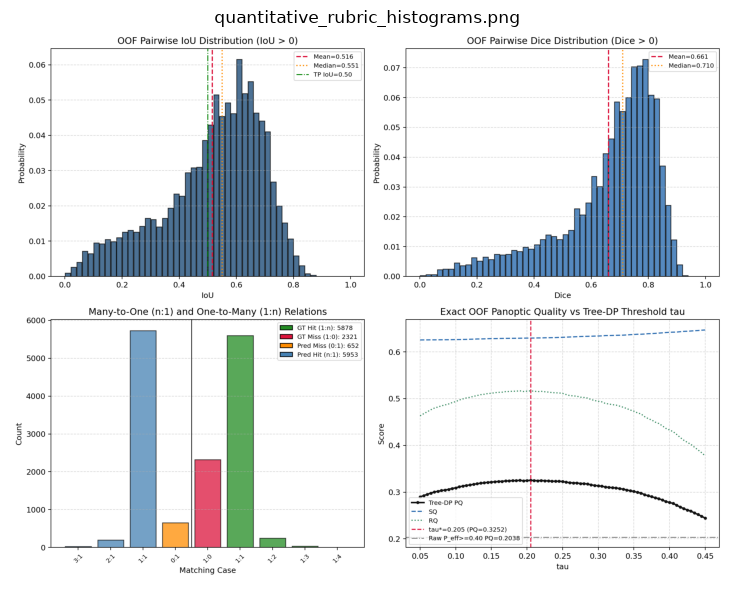

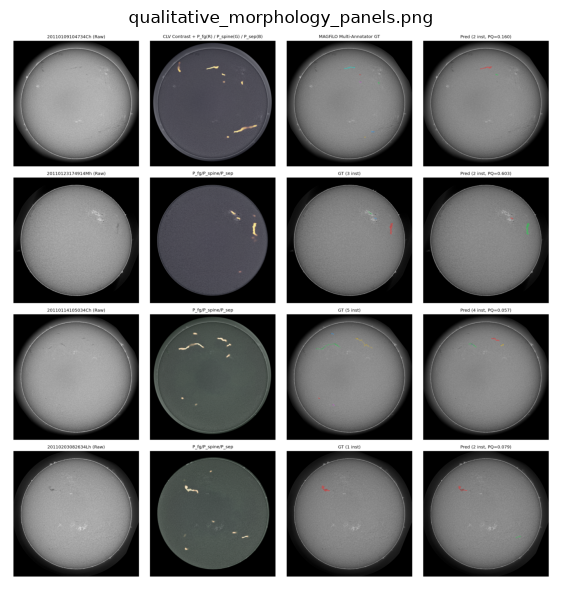

In [3]:
OUT_DIR = None
for cand in [REPO_ROOT / 'out', REPO_ROOT.parent / 'out', REPO_ROOT / 'dry_run_out']:
    if (cand / 'run_metrics.json').exists():
        OUT_DIR = cand
        break

if OUT_DIR is not None:
    rel_out = os.path.relpath(OUT_DIR, REPO_ROOT).replace('\\', '/')
    print('Inspecting metrics from:', rel_out)
    with open(OUT_DIR / 'run_metrics.json', 'r', encoding='utf-8') as f:
        metrics = json.load(f)
    print(json.dumps(metrics['oof_metrics'], indent=2))
    for png_name in ['quantitative_rubric_histograms.png', 'qualitative_morphology_panels.png']:
        p = OUT_DIR / png_name
        if p.exists():
            fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
            ax.imshow(mpimg.imread(p))
            ax.axis('off')
            ax.set_title(png_name)
            plt.tight_layout()
            plt.show()
else:
    print('No full training run_metrics.json found locally; predict-only outputs verified in: dry_run_out')